In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

# to load all 6 supplied datasets
bbb = pd.read_csv('ball_by_ball.csv')
matches = pd.read_csv('matches.csv')
comp = pd.read_csv('competitions.csv')
mapping = pd.read_csv('competition_team_player_mapping.csv')
p11 = pd.read_csv('playing_eleven.csv')
teams = pd.read_csv('teams.csv')

print(f"Loaded ball_by_ball: {bbb.shape} | matches: {matches.shape} | competitions: {comp.shape}")
print(f"Loaded playing_eleven: {p11.shape} | mapping: {mapping.shape} | teams: {teams.shape}")

Loaded ball_by_ball: (200999, 33) | matches: (883, 22) | competitions: (141, 4)
Loaded playing_eleven: (28381, 9) | mapping: (6413, 6) | teams: (353, 3)


In [ ]:
# merge match & competition metadata onto ball-by-ball records
m_full = matches.merge(comp, on='comp_id', how='left')
df = bbb.merge(
    m_full[['match_id', 'comp_id', 'comp_name', 'match_format', 'season', 'match_date',
            'stage', 'home_team', 'away_team', 'first_inn_revised_overs',
            'second_inn_revised_overs', 'revised_target', 'knock_out', 'win_team_id']],
    on='match_id',
    how='left'
)

# sort chronologically within every match and innings
df = df.sort_values(['match_id', 'innings', 'innings_ball_num']).reset_index(drop=True)

# delivery-level legal ball, batter ball, runs, and wicket flags
df['is_legal'] = ~df['extras_type'].isin(['wide', 'Overstep', 'other'])
df['is_bat_ball'] = df['extras_type'] != 'wide'
df['total_runs'] = df['runs'] + df['extras1_runs'] + df['extras_2_runs']
df['bowler_runs'] = df['runs'] + np.where(df['extras_type'].isin(['wide', 'Overstep', 'other']), df['extras1_runs'], 0)

# exclude non-bowler dismissals (RunOut, Retire Out, Obstructing the field)
non_bowler_wkts = ['RunOut', 'Retire Out', 'Obstracting the field', 'Obstructing the field']
df['is_bowler_wkt'] = df['is_wicket'] & (~df['dismissal_type'].isin(non_bowler_wkts))

df['is_boundary'] = df['is_four'] | df['is_six']
df['is_dot_bat'] = df['is_bat_ball'] & (df['runs'] == 0)
df['is_dot_bowl'] = df['is_legal'] & (df['bowler_runs'] == 0)

# separate Super Overs (innings 3 & 4) from regular 20-over innings (1 & 2)
super_overs = df[df['innings'].isin([3, 4])].copy()
reg = df[df['innings'].isin([1, 2])].copy()

print(f"Regular deliveries: {len(reg)} | Super Over deliveries excluded from baseline state: {len(super_overs)}")

Regular deliveries: 200961 | Super Over deliveries excluded from baseline state: 38


In [ ]:
# Pre-ball cumulative runs, wickets, and legal balls bowled
reg['cum_runs_before'] = reg.groupby(['match_id', 'innings'])['total_runs'].cumsum() - reg['total_runs']
reg['cum_wkts_before'] = reg.groupby(['match_id', 'innings'])['is_wicket'].cumsum() - reg['is_wicket'].astype(int)
reg['legal_balls_before'] = reg.groupby(['match_id', 'innings'])['is_legal'].cumsum() - reg['is_legal'].astype(int)

# DLS-aware max overs and balls remaining
reg['max_overs'] = np.where(reg['innings'] == 1, reg['first_inn_revised_overs'].fillna(20.0), reg['second_inn_revised_overs'].fillna(20.0))
reg['max_balls'] = (reg['max_overs'] * 6).round().astype(int)
reg['balls_remaining'] = (reg['max_balls'] - reg['legal_balls_before']).clip(lower=1)

# 1st-innings totals and 2nd-innings target / Required Run Rate (RRR)
inn1_totals = reg[reg['innings'] == 1].groupby('match_id')['total_runs'].sum().rename('inn1_total')
reg = reg.merge(inn1_totals, on='match_id', how='left')

reg['target'] = np.where(
    reg['innings'] == 2,
    np.where(reg['revised_target'].notna() & (reg['revised_target'] > 0), reg['revised_target'], reg['inn1_total'] + 1),
    np.nan
)
reg['runs_needed'] = np.where(reg['innings'] == 2, (reg['target'] - reg['cum_runs_before']).clip(lower=1), np.nan)
reg['rrr'] = np.where(reg['innings'] == 2, reg['runs_needed'] * 6.0 / reg['balls_remaining'], np.nan)
reg['crr'] = np.where(reg['legal_balls_before'] > 0, reg['cum_runs_before'] * 6.0 / reg['legal_balls_before'], 8.0)

# Empirical Win Probability Model for 2nd-innings chases
reg['bat_team_won'] = np.where(reg['win_team_id'].notna(), (reg['batting_team_id'] == reg['win_team_id']).astype(int), np.nan)
inn2_train = reg[(reg['innings'] == 2) & (reg['bat_team_won'].notna()) & (reg['rrr'].notna())].copy()
inn2_train['wkts_left'] = 10 - inn2_train['cum_wkts_before']
inn2_train['rrr_capped'] = inn2_train['rrr'].clip(0, 36)
inn2_train['rrr_x_wkts'] = inn2_train['rrr_capped'] * inn2_train['wkts_left']

clf2 = LogisticRegression(max_iter=500).fit(
    inn2_train[['rrr_capped', 'wkts_left', 'balls_remaining', 'runs_needed', 'rrr_x_wkts']],
    inn2_train['bat_team_won']
)

def pred_wp2(rrr, wkts_left, balls_rem, runs_need):
    rrr_c = np.clip(rrr, 0, 36)
    X = pd.DataFrame({
        'rrr_capped': rrr_c, 'wkts_left': wkts_left,
        'balls_remaining': balls_rem, 'runs_needed': runs_need,
        'rrr_x_wkts': rrr_c * wkts_left
    })
    return clf2.predict_proba(X)[:, 1]

inn2_mask = (reg['innings'] == 2) & (reg['rrr'].notna())
sub2 = reg[inn2_mask]
reg.loc[inn2_mask, 'wp_before'] = pred_wp2(
    sub2['runs_needed'] * 6.0 / sub2['balls_remaining'],
    10 - sub2['cum_wkts_before'], sub2['balls_remaining'], sub2['runs_needed']
)

# Composite Pressure Score (0 to 100)
exp_wkts = 6.5 * (reg['legal_balls_before'] / reg['max_balls'])
wkt_deficit = (reg['cum_wkts_before'] - exp_wkts).clip(lower=0)
wkt_pressure = np.clip(0.5 * (wkt_deficit / 3.0) + 0.5 * (reg['cum_wkts_before'] / 7.0), 0, 1)

rrr_active = np.where(reg['rrr'] <= 24, np.clip((reg['rrr'] - 6.0) / 8.0, 0, 1), np.clip(1.0 - (reg['rrr'] - 24.0) / 12.0, 0.2, 1.0))
inn1_deficit = np.clip((8.5 - reg['crr']) / 4.0, 0, 1)
inn1_stage_push = np.clip((reg['overid'] - 10) / 10.0, 0, 1) * 0.65
rate_pressure = np.where(reg['innings'] == 2, rrr_active, np.maximum(inn1_deficit, inn1_stage_push))

death_factor = np.clip((reg['overid'] - 12) / 8.0, 0, 1)
closeness_inn2 = np.where(
    reg['innings'] == 2,
    np.clip(1.0 - 2.0 * np.abs(reg['wp_before'].fillna(0.5) - 0.5), 0, 1),
    0.45 * death_factor + 0.25 * (wkt_pressure > 0.5).astype(float)
)
endgame_pressure = np.clip(0.55 * death_factor + 0.45 * closeness_inn2, 0, 1)
is_high_stakes = (reg['knock_out'] == 1) | (reg['stage'].isin(['Final', 'Qualifier', 'Eliminator', 'Semi Final', 'Super 4']))

reg['pressure_score'] = np.clip(
    100 * (0.35 * rate_pressure + 0.35 * wkt_pressure + 0.30 * endgame_pressure) + np.where(is_high_stakes, 12.0, 0.0),
    0, 100
)
reg['is_pressure'] = reg['pressure_score'] >= 40.0

# Competition Tier Weighting & Match+Over Context Baselines
full_members = {'India', 'Australia', 'England', 'South Africa', 'New Zealand', 'Pakistan', 'Sri Lanka', 'West Indies', 'Bangladesh', 'Afghanistan'}
ipl_comps = {'IPL 2022', 'IPL 2023', 'IPL 2024', 'IPL 2025', 'IPL 2026'}
emerging_comps = {'Asia Cup Rising Stars 2025', 'Mens T20 Emerging Teams Asia Cup 2024'}

def get_tier(row):
    if row['comp_name'] in ipl_comps: return 1.00
    elif row['comp_name'] in emerging_comps: return 0.65
    elif (row['home_team'] in full_members) and (row['away_team'] in full_members): return 0.92
    else: return 0.72

reg['comp_tier_weight'] = reg.apply(get_tier, axis=1)

co_base = reg.groupby(['comp_name', 'innings', 'overid']).agg(co_bat=('runs', 'mean'), co_bowl=('bowler_runs', 'mean')).reset_index()
mi_base = reg.groupby(['match_id', 'innings']).agg(mi_bat=('runs', 'mean'), mi_bowl=('bowler_runs', 'mean')).reset_index()
reg = reg.merge(co_base, on=['comp_name', 'innings', 'overid'], how='left').merge(mi_base, on=['match_id', 'innings'], how='left')

reg['bat_val'] = (reg['runs'] - (0.5 * reg['co_bat'] + 0.5 * reg['mi_bat'])) * reg['comp_tier_weight']
reg['bowl_val'] = ((0.5 * reg['co_bowl'] + 0.5 * reg['mi_bowl']) - reg['bowler_runs']) * reg['comp_tier_weight']

print("High-Pressure Delivery Share:", round(reg['is_pressure'].mean() * 100, 2), "%")
print(reg.groupby('is_pressure')[['overid', 'cum_wkts_before', 'rrr', 'is_wicket']].mean())

High-Pressure Delivery Share: 29.81 %
                overid  cum_wkts_before        rrr  is_wicket
is_pressure                                                  
False         8.070058         1.669531   8.433380   0.045911
True         14.900880         5.070459  16.918283   0.073314


In [ ]:
bat_df = reg[reg['is_bat_ball']].copy()

def agg_batting(sub, pfx):
    g = sub.groupby(['striker_id', 'striker_name']).agg(
        balls=('runs', 'count'),
        matches=('match_id', 'nunique'),
        runs=('runs', 'sum'),
        fours=('is_four', 'sum'),
        sixes=('is_six', 'sum'),
        dots=('is_dot_bat', 'sum'),
        dismissals=('is_wicket', 'sum'),
        bat_val_sum=('bat_val', 'sum'),
        avg_pressure=('pressure_score', 'mean')
    ).reset_index()
    g['sr'] = g['runs'] * 100.0 / g['balls']
    g['bdry_pct'] = (g['fours'] + g['sixes']) * 100.0 / g['balls']
    g['dot_pct'] = g['dots'] * 100.0 / g['balls']
    g['bpd'] = g['balls'] / g['dismissals'].clip(lower=1)
    g['avg'] = g['runs'] / g['dismissals'].clip(lower=1)
    g['ctx_val_100'] = g['bat_val_sum'] * 100.0 / g['balls']
    return g.rename(columns={c: f'{pfx}_{c}' for c in g.columns if c not in ['striker_id', 'striker_name']})

bat_press = agg_batting(bat_df[bat_df['is_pressure']], 'p')
bat_norm = agg_batting(bat_df[~bat_df['is_pressure']], 'n')

# Match-by-match pressure consistency (min 4 balls per pressure appearance)
bat_match = bat_df[bat_df['is_pressure']].groupby(['striker_id', 'match_id']).agg(
    m_balls=('runs', 'count'),
    m_val=('bat_val', 'sum')
).reset_index()
bat_match = bat_match[bat_match['m_balls'] >= 4]
bat_cons = bat_match.groupby('striker_id').agg(
    p_qual_innings=('match_id', 'count'),
    p_pos_innings=('m_val', lambda x: (x > 0).mean())
).reset_index()

bat_all = bat_press.merge(bat_norm, on=['striker_id', 'striker_name'], how='left').merge(bat_cons, on='striker_id', how='left')
bat_elig = bat_all[(bat_all['p_balls'] >= 150) & (bat_all['n_balls'] >= 100) & (bat_all['p_qual_innings'] >= 12)].copy()
bat_elig['sr_delta'] = bat_elig['p_sr'] - bat_elig['n_sr']

print(f"Eligible Batters (>=150 pressure balls, >=12 pressure innings): {len(bat_elig)}")

Eligible Batters (>=150 pressure balls, >=12 pressure innings): 80


In [ ]:
def agg_bowling(sub, pfx):
    g = sub.groupby(['bowler_id', 'bowler_name']).agg(
        legal_balls=('is_legal', 'sum'),
        matches=('match_id', 'nunique'),
        runs_conceded=('bowler_runs', 'sum'),
        wkts=('is_bowler_wkt', 'sum'),
        dots=('is_dot_bowl', 'sum'),
        bdrys=('is_boundary', 'sum'),
        bowl_val_sum=('bowl_val', 'sum'),
        avg_pressure=('pressure_score', 'mean'),
        avg_tier=('comp_tier_weight', 'mean')
    ).reset_index()
    g['econ'] = g['runs_conceded'] * 6.0 / g['legal_balls'].clip(lower=1)
    g['sr'] = g['legal_balls'] / g['wkts'].clip(lower=1)
    g['wkt_pct'] = g['wkts'] * 100.0 / g['legal_balls'].clip(lower=1)
    g['tier_wkt_pct'] = g['wkt_pct'] * g['avg_tier']
    g['dot_pct'] = g['dots'] * 100.0 / g['legal_balls'].clip(lower=1)
    g['ctx_rs_24'] = g['bowl_val_sum'] * 24.0 / g['legal_balls'].clip(lower=1)
    return g.rename(columns={c: f'{pfx}_{c}' for c in g.columns if c not in ['bowler_id', 'bowler_name']})

bowl_press = agg_bowling(reg[reg['is_pressure']], 'p')
bowl_norm = agg_bowling(reg[~reg['is_pressure']], 'n')

# Match-by-match spell consistency (min 4 legal balls per pressure spell)
bowl_match = reg[reg['is_pressure']].groupby(['bowler_id', 'match_id']).agg(
    m_balls=('is_legal', 'sum'),
    m_val=('bowl_val', 'sum'),
    m_wkts=('is_bowler_wkt', 'sum'),
    m_tier=('comp_tier_weight', 'first')
).reset_index()
bowl_match = bowl_match[bowl_match['m_balls'] >= 4]
bowl_match['m_imp'] = (bowl_match['m_val'] + 6.0 * bowl_match['m_wkts'] * bowl_match['m_tier']) / bowl_match['m_balls']

bowl_cons = bowl_match.groupby('bowler_id').agg(
    p_qual_spells=('match_id', 'count'),
    p_pos_spells=('m_imp', lambda x: (x > 0).mean())
).reset_index()

bowl_all = bowl_press.merge(bowl_norm, on=['bowler_id', 'bowler_name'], how='left').merge(bowl_cons, on='bowler_id', how='left')
bowl_elig = bowl_all[(bowl_all['p_legal_balls'] >= 150) & (bowl_all['n_legal_balls'] >= 150) & (bowl_all['p_qual_spells'] >= 15)].copy()
bowl_elig['econ_diff'] = (bowl_elig['n_econ'] - bowl_elig['p_econ']) * bowl_elig['p_avg_tier']

print(f"Eligible Bowlers (>=150 pressure legal balls, >=15 pressure spells): {len(bowl_elig)}")

Eligible Bowlers (>=150 pressure legal balls, >=15 pressure spells): 118


In [ ]:
# 1. Supervised Win-Impact Models (Random Forest & Gradient Boosting) for Feature Importance
bat_win = bat_df[bat_df['is_pressure'] & bat_df['bat_team_won'].notna()].groupby(['striker_id', 'match_id']).agg(
    won=('bat_team_won', 'first'),
    m_sr=('runs', lambda x: x.sum() * 100.0 / len(x)),
    m_bdry=('is_boundary', 'mean'),
    m_dot=('is_dot_bat', 'mean'),
    m_out=('is_wicket', 'sum'),
    m_val=('bat_val', 'mean')
).reset_index()

rf_bat = RandomForestRegressor(n_estimators=200, max_depth=5, random_state=42).fit(
    bat_win[['m_sr', 'm_bdry', 'm_dot', 'm_out', 'm_val']], bat_win['won']
)
gb_bat = GradientBoostingRegressor(n_estimators=150, max_depth=3, random_state=42).fit(
    bat_win[['m_sr', 'm_bdry', 'm_dot', 'm_out', 'm_val']], bat_win['won']
)

reg['bowl_team_won'] = np.where(reg['win_team_id'].notna(), (reg['bowling_team_id'] == reg['win_team_id']).astype(int), np.nan)
bowl_win = reg[reg['is_pressure'] & reg['bowl_team_won'].notna()].groupby(['bowler_id', 'match_id']).agg(
    won=('bowl_team_won', 'first'),
    m_econ=('bowler_runs', lambda x: x.sum() * 6.0 / len(x)),
    m_wkts=('is_bowler_wkt', 'sum'),
    m_dot=('is_dot_bowl', 'mean'),
    m_bdry=('is_boundary', 'mean'),
    m_val=('bowl_val', 'mean')
).reset_index()

rf_bowl = RandomForestRegressor(n_estimators=200, max_depth=5, random_state=42).fit(
    bowl_win[['m_econ', 'm_wkts', 'm_dot', 'm_bdry', 'm_val']], bowl_win['won']
)
gb_bowl = GradientBoostingRegressor(n_estimators=150, max_depth=3, random_state=42).fit(
    bowl_win[['m_econ', 'm_wkts', 'm_dot', 'm_bdry', 'm_val']], bowl_win['won']
)

# 2. Unsupervised K-Means Clustering to discover player pressure archetypes
bat_elig['cluster'] = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(
    StandardScaler().fit_transform(bat_elig[['p_ctx_val_100', 'p_sr', 'p_bpd', 'p_dot_pct', 'p_pos_innings']])
)
bowl_elig['cluster'] = KMeans(n_clusters=3, random_state=42, n_init=10).fit_predict(
    StandardScaler().fit_transform(bowl_elig[['p_ctx_rs_24', 'p_tier_wkt_pct', 'p_dot_pct', 'econ_diff', 'p_pos_spells']])
)

print("Batting RF Feature Importances:", dict(zip(['Strike Rate', 'Boundary %', 'Dot %', 'Dismissals', 'Context Value'], np.round(rf_bat.feature_importances_, 3))))
print("Bowling RF Feature Importances:", dict(zip(['Economy', 'Wickets', 'Dot %', 'Boundary %', 'Context Value'], np.round(rf_bowl.feature_importances_, 3))))


Batting RF Feature Importances: {'Strike Rate': np.float64(0.456), 'Boundary %': np.float64(0.03), 'Dot %': np.float64(0.115), 'Dismissals': np.float64(0.132), 'Context Value': np.float64(0.268)}
Bowling RF Feature Importances: {'Economy': np.float64(0.486), 'Wickets': np.float64(0.043), 'Dot %': np.float64(0.168), 'Boundary %': np.float64(0.046), 'Context Value': np.float64(0.257)}


In [ ]:
from sklearn.metrics import r2_score
from sklearn.model_selection import cross_val_score

# Cross-validate win-impact models & verify pressure separation
cv_bat = cross_val_score(rf_bat, bat_win[['m_sr', 'm_bdry', 'm_dot', 'm_out', 'm_val']], bat_win['won'], cv=5, scoring='r2')
cv_bowl = cross_val_score(rf_bowl, bowl_win[['m_econ', 'm_wkts', 'm_dot', 'm_bdry', 'm_val']], bowl_win['won'], cv=5, scoring='r2')

print(f"Batting Win-Impact RF 5-Fold R2: {cv_bat.mean():.4f} (+/- {cv_bat.std():.4f})")
print(f"Bowling Win-Impact RF 5-Fold R2: {cv_bowl.mean():.4f} (+/- {cv_bowl.std():.4f})")
print("\nBatting Cluster Profiles (Means):")
print(bat_elig.groupby('cluster')[['p_sr', 'p_bpd', 'p_dot_pct', 'p_ctx_val_100', 'p_pos_innings']].mean().round(2))
print("\nBowling Cluster Profiles (Means):")
print(bowl_elig.groupby('cluster')[['p_econ', 'p_sr', 'p_dot_pct', 'p_ctx_rs_24', 'p_pos_spells']].mean().round(2))

Batting Win-Impact RF 5-Fold R2: 0.1065 (+/- 0.0225)
Bowling Win-Impact RF 5-Fold R2: 0.1188 (+/- 0.0221)

Batting Cluster Profiles (Means):
           p_sr  p_bpd  p_dot_pct  p_ctx_val_100  p_pos_innings
cluster                                                        
0        175.51  18.90      28.59          29.20           0.68
1        136.77  14.74      34.95           4.73           0.49
2        160.96  14.15      33.01          20.15           0.66

Bowling Cluster Profiles (Means):
         p_econ   p_sr  p_dot_pct  p_ctx_rs_24  p_pos_spells
cluster                                                     
0          9.02  16.46      36.26        -0.64          0.65
1          7.88  12.10      40.66         2.13          0.77
2         10.52  15.65      31.89        -4.27          0.55


In [ ]:
def eb_shrink(val, n, prior_mean, k=180):
    return (n * val + k * prior_mean) / (n + k)

def zscore(s):
    return (s - s.mean()) / s.std(ddof=0)

# --- Batting Pressure Rating ---
b = bat_elig.copy()
b['raw_score'] = (
    0.35 * zscore(eb_shrink(b['p_ctx_val_100'], b['p_balls'], b['p_ctx_val_100'].mean(), 180)) +
    0.20 * zscore(eb_shrink(b['p_bpd'], b['p_balls'], b['p_bpd'].mean(), 150)) +
    0.15 * (-zscore(eb_shrink(b['p_dot_pct'], b['p_balls'], b['p_dot_pct'].mean(), 150))) +
    0.15 * zscore(eb_shrink(b['sr_delta'], b['p_balls'], b['sr_delta'].mean(), 180)) +
    0.15 * zscore(eb_shrink(b['p_pos_innings'], b['p_qual_innings'], b['p_pos_innings'].mean(), 12))
)
b['pressure_rating'] = 50 + 15 * zscore(b['raw_score'])
top10_batters = b.sort_values('pressure_rating', ascending=False).head(10).reset_index(drop=True)
top10_batters['rank'] = top10_batters.index + 1

# --- Bowling Pressure Rating ---
w = bowl_elig.copy()
w['raw_score'] = (
    0.35 * zscore(eb_shrink(w['p_ctx_rs_24'], w['p_legal_balls'], w['p_ctx_rs_24'].mean(), 200)) +
    0.25 * zscore(eb_shrink(w['p_tier_wkt_pct'], w['p_legal_balls'], w['p_tier_wkt_pct'].mean(), 200)) +
    0.15 * zscore(eb_shrink(w['p_dot_pct'] * w['p_avg_tier'], w['p_legal_balls'], (w['p_dot_pct'] * w['p_avg_tier']).mean(), 180)) +
    0.10 * zscore(eb_shrink(w['econ_diff'], w['p_legal_balls'], w['econ_diff'].mean(), 180)) +
    0.15 * zscore(eb_shrink(w['p_pos_spells'], w['p_qual_spells'], w['p_pos_spells'].mean(), 14))
)
w['pressure_rating'] = 50 + 15 * zscore(w['raw_score'])
top10_bowlers = w.sort_values('pressure_rating', ascending=False).head(10).reset_index(drop=True)
top10_bowlers['rank'] = top10_bowlers.index + 1

print("=== TOP 10 BATTERS UNDER PRESSURE ===")
print(top10_batters[['rank', 'striker_id', 'striker_name', 'p_balls', 'p_sr', 'n_sr', 'p_avg', 'p_pos_innings', 'pressure_rating']].to_string(index=False))

print("\n=== TOP 10 BOWLERS UNDER PRESSURE ===")
print(top10_bowlers[['rank', 'bowler_id', 'bowler_name', 'p_legal_balls', 'p_wkts', 'p_econ', 'n_econ', 'p_pos_spells', 'pressure_rating']].to_string(index=False))

=== TOP 10 BATTERS UNDER PRESSURE ===
 rank  striker_id         striker_name  p_balls       p_sr       n_sr     p_avg  p_pos_innings  pressure_rating
    1        2756       Shashank Singh      361 179.224377 129.648241 53.916667       0.576923        81.173641
    2         813          Jos Buttler      279 194.982079 151.058824 27.200000       0.833333        79.267160
    3         143       Dinesh Karthik      472 187.288136 110.778443 28.516129       0.634146        78.242843
    4        1699     Suryakumar Yadav      593 186.677909 160.710988 39.535714       0.702703        77.468218
    5       37052           Naman Dhir      229 195.196507 151.388889 26.294118       0.761905        72.612303
    6        6396            Tim David      613 189.722675 165.579119 33.228571       0.729167        72.270447
    7       20702       Tristan Stubbs      586 169.965870 125.252525 35.571429       0.589744        71.538475
    8        3125      Nicholas Pooran      507 180.867850 148.873

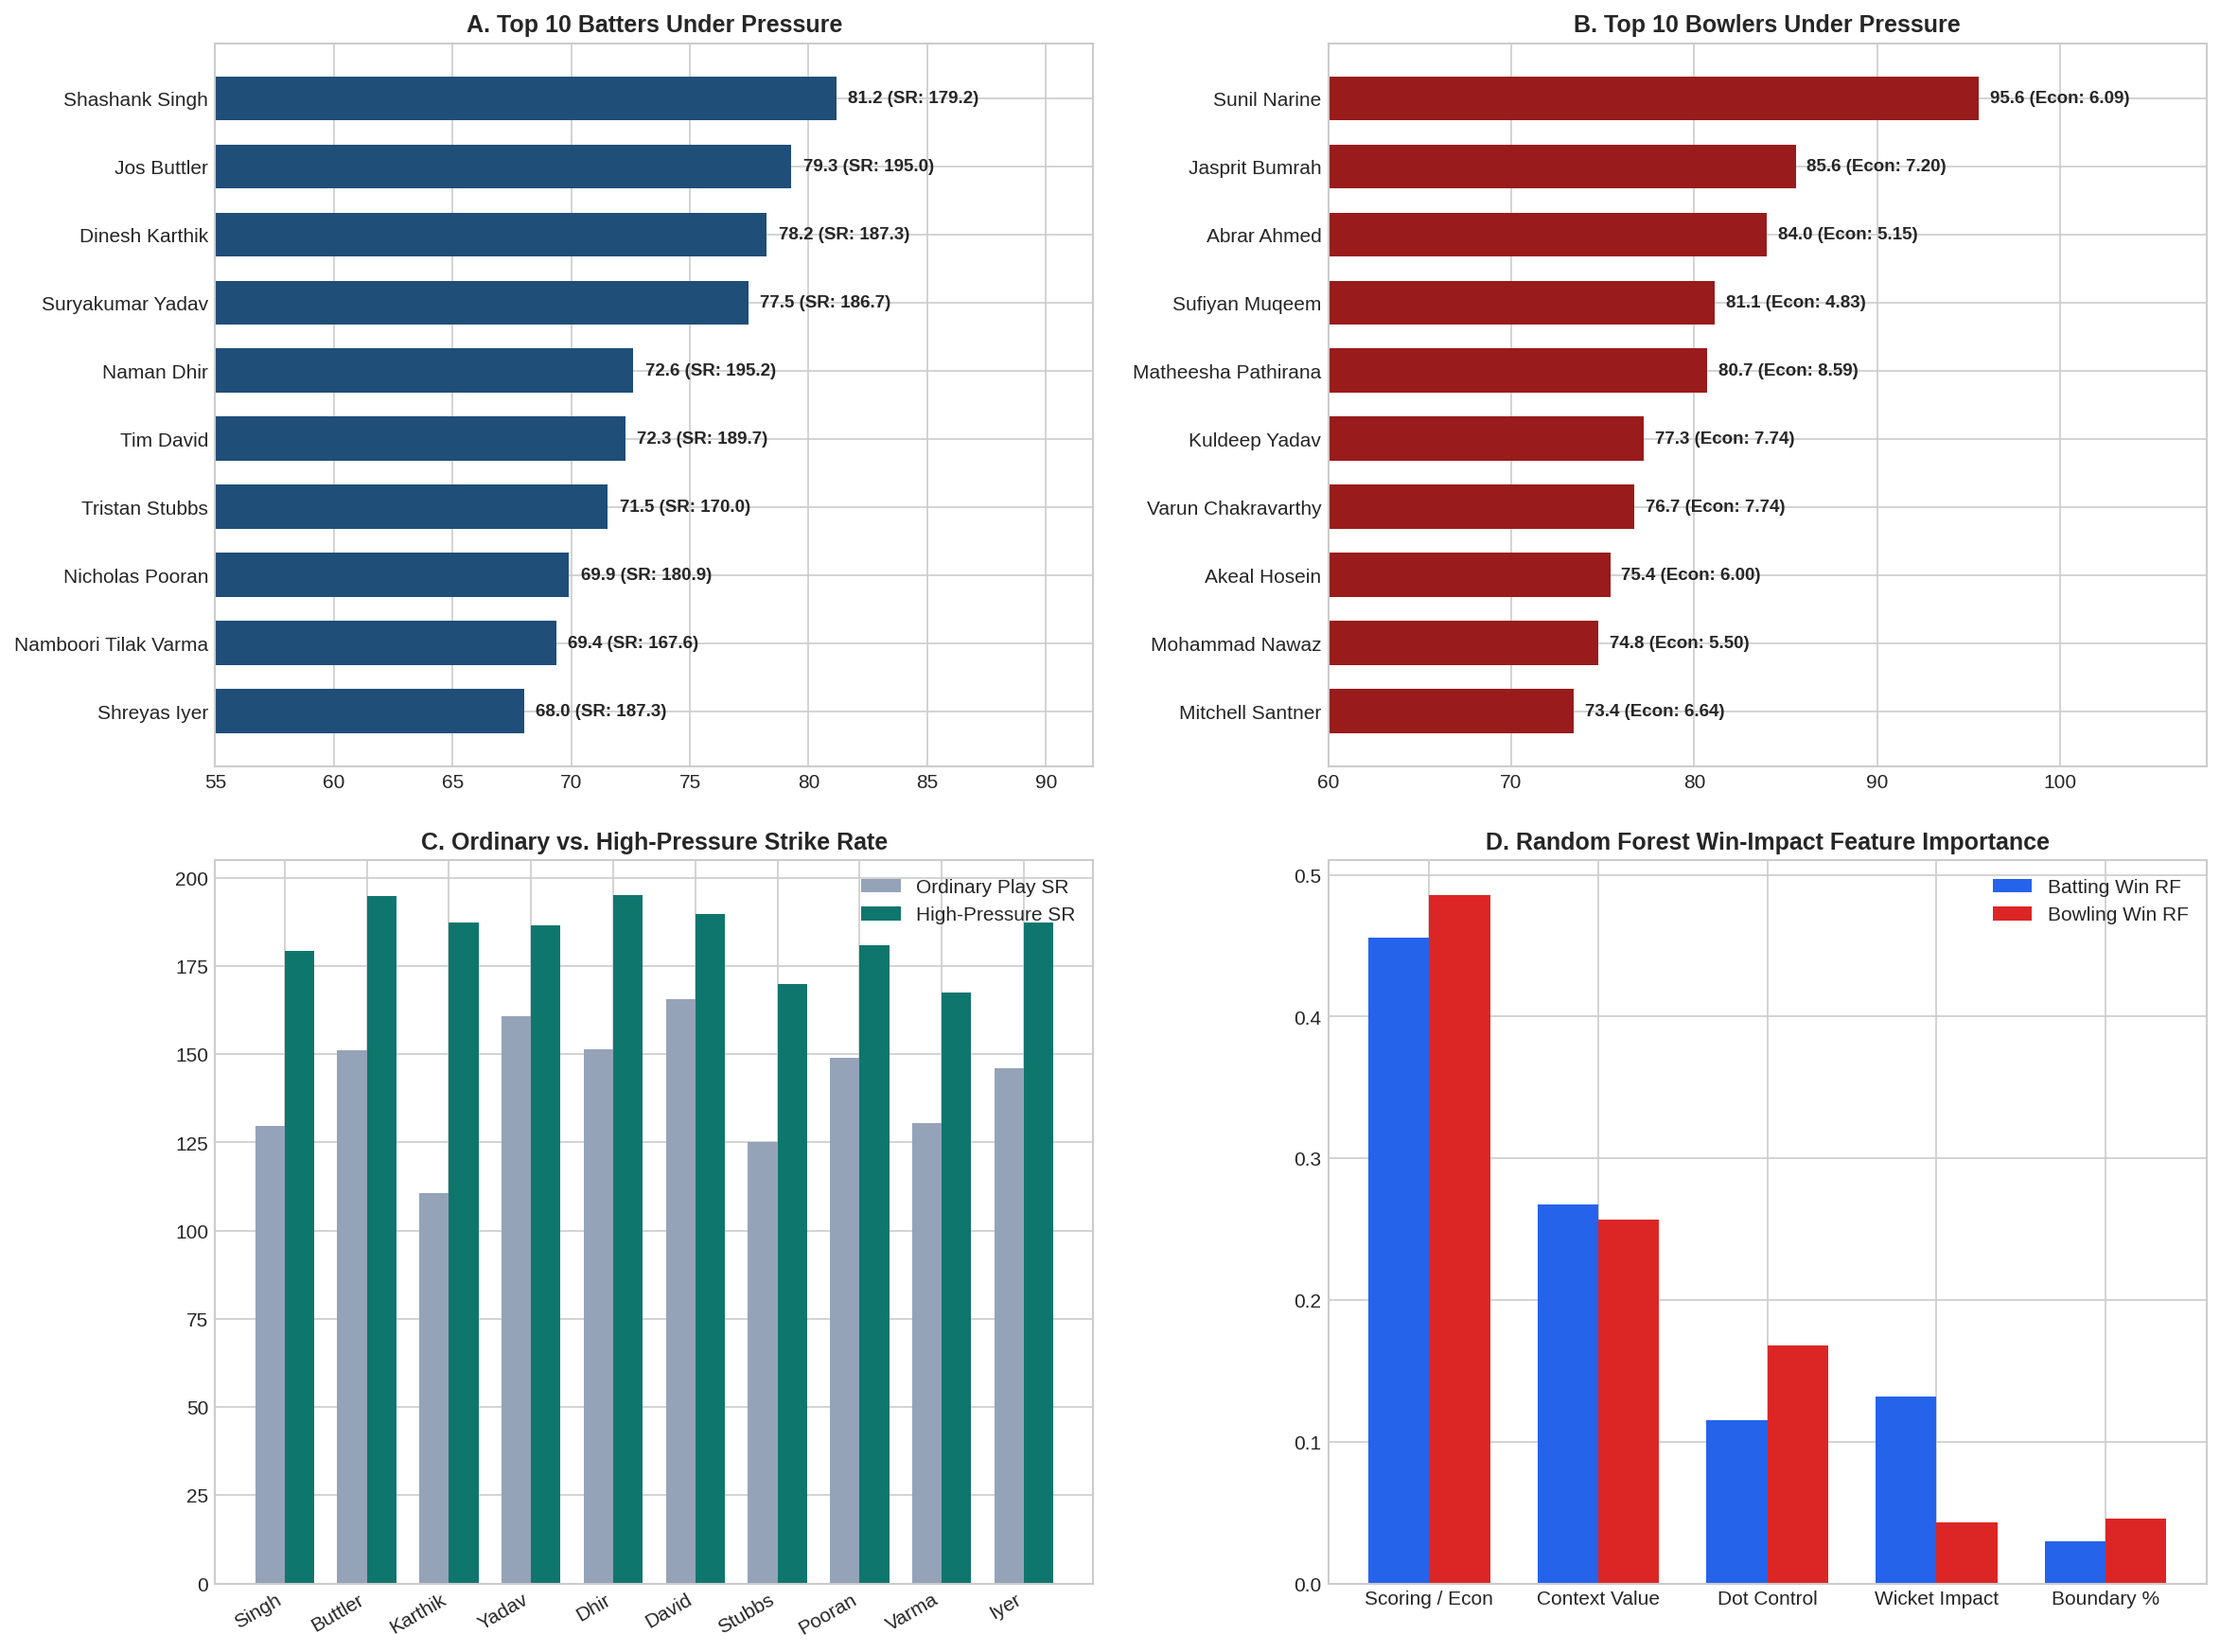

In [ ]:
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(2, 2, figsize=(16, 12), dpi=150)

# Panel A: Top 10 Batters
t10b = top10_batters.iloc[::-1]
axes[0, 0].barh(t10b['striker_name'], t10b['pressure_rating'], color='#1f4e78', height=0.65)
for idx, (_, r) in enumerate(t10b.iterrows()):
    axes[0, 0].text(r['pressure_rating'] + 0.5, idx, f"{r['pressure_rating']:.1f} (SR: {r['p_sr']:.1f})", va='center', fontsize=9, fontweight='bold')
axes[0, 0].set_xlim(55, 92)
axes[0, 0].set_title('A. Top 10 Batters Under Pressure', fontsize=12, fontweight='bold')

# Panel B: Top 10 Bowlers
t10w = top10_bowlers.iloc[::-1]
axes[0, 1].barh(t10w['bowler_name'], t10w['pressure_rating'], color='#991b1b', height=0.65)
for idx, (_, r) in enumerate(t10w.iterrows()):
    axes[0, 1].text(r['pressure_rating'] + 0.6, idx, f"{r['pressure_rating']:.1f} (Econ: {r['p_econ']:.2f})", va='center', fontsize=9, fontweight='bold')
axes[0, 1].set_xlim(60, 108)
axes[0, 1].set_title('B. Top 10 Bowlers Under Pressure', fontsize=12, fontweight='bold')

# Panel C: Ordinary vs High-Pressure Strike Rate
x = np.arange(len(top10_batters))
w_bar = 0.36
axes[1, 0].bar(x - w_bar/2, top10_batters['n_sr'], width=w_bar, label='Ordinary Play SR', color='#94a3b8')
axes[1, 0].bar(x + w_bar/2, top10_batters['p_sr'], width=w_bar, label='High-Pressure SR', color='#0f766e')
axes[1, 0].set_xticks(x)
axes[1, 0].set_xticklabels([n.split()[-1] for n in top10_batters['striker_name']], rotation=30, ha='right')
axes[1, 0].set_title('C. Ordinary vs. High-Pressure Strike Rate', fontsize=12, fontweight='bold')
axes[1, 0].legend()

# Panel D: Random Forest Feature Importances
feat_names = ['Scoring / Econ', 'Context Value', 'Dot Control', 'Wicket Impact', 'Boundary %']
bat_imp = [rf_bat.feature_importances_[0], rf_bat.feature_importances_[4], rf_bat.feature_importances_[2], rf_bat.feature_importances_[3], rf_bat.feature_importances_[1]]
bowl_imp = [rf_bowl.feature_importances_[0], rf_bowl.feature_importances_[4], rf_bowl.feature_importances_[2], rf_bowl.feature_importances_[1], rf_bowl.feature_importances_[3]]
xf = np.arange(len(feat_names))
axes[1, 1].bar(xf - w_bar/2, bat_imp, width=w_bar, label='Batting Win RF', color='#2563eb')
axes[1, 1].bar(xf + w_bar/2, bowl_imp, width=w_bar, label='Bowling Win RF', color='#dc2626')
axes[1, 1].set_xticks(xf)
axes[1, 1].set_xticklabels(feat_names)
axes[1, 1].set_title('D. Random Forest Win-Impact Feature Importance', fontsize=12, fontweight='bold')
axes[1, 1].legend()

plt.tight_layout(pad=2.0)
plt.savefig('superr_selector_pressure_analysis.png', bbox_inches='tight')
plt.show()

In [ ]:
from google.colab import files

top10_batters.to_csv('top_10_batters_under_pressure.csv', index=False)
top10_bowlers.to_csv('top_10_bowlers_under_pressure.csv', index=False)
b.sort_values('pressure_rating', ascending=False).to_csv('all_eligible_batters_ranked.csv', index=False)
w.sort_values('pressure_rating', ascending=False).to_csv('all_eligible_bowlers_ranked.csv', index=False)

# Download CSVs & chart directly from Google Colab
files.download('top_10_batters_under_pressure.csv')
files.download('top_10_bowlers_under_pressure.csv')
files.download('superr_selector_pressure_analysis.png')
print("All ranking CSVs and high-resolution report visuals exported!")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

All ranking CSVs and high-resolution report visuals exported!
